**Week 7 - Advanced Models**

*   Try Gradient Boosting (e.g., XGBoost or LightGBM)
*   Perform light hyperparameter tuning (depth, learning rate, n_estimators)
*   **Deliverable**: 05_advanced_models.ipyng with test metrics



In [ ]:
import os
import glob
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import lightgbm as lgb
import xgboost as xgb
from sklearn.model_selection import KFold
from sklearn.neighbors import BallTree
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

try:
    import geopandas as gpd
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "geopandas"])
    import geopandas as gpd

warnings.filterwarnings("ignore")

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
CSV_DIR = "/content/drive/MyDrive/csv"
DATA_DIR = "/content/drive/MyDrive/output"
DISTRICT_FILE = "/content/drive/MyDrive/school_districts/california_school_district_areas_2024-25.geojson"

X_MONTHS = 24
VALID_MONTHS = 2
SEED = 42

In [ ]:
def build_unscaled_file(out_path):
    needed = ["ClosePrice", "CloseDate", "PropertyType", "PropertySubType", "LivingArea", "BedroomsTotal",
              "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt", "City", "PostalCode",
              "Latitude", "Longitude", "latfilled", "lonfilled"]

    files = glob.glob(os.path.join(CSV_DIR, "CRMLSSold*.csv"))
    print(f"Found {len(files)} files")
    raw = pd.concat([pd.read_csv(f, usecols=lambda c: c in needed, low_memory=False) for f in files],
                    ignore_index=True)
    print(f"Loaded {len(raw):,} rows")

    raw = raw[(raw["PropertyType"] == "Residential") & (raw["PropertySubType"] == "SingleFamilyResidence")].copy()
    raw["CloseDate"] = pd.to_datetime(raw["CloseDate"], errors="coerce")
    print(f"Rows after filtering to Residential / SingleFamilyResidence: {len(raw):,}")

    bad_rows = {
        "ClosePrice":            (raw["ClosePrice"] <= 10_000) | (raw["ClosePrice"] > 20_000_000),
        "LivingArea":            (raw["LivingArea"] <= 100) | (raw["LivingArea"] > 15_000),
        "BedroomsTotal":         (raw["BedroomsTotal"] <= 0) | (raw["BedroomsTotal"] > 12),
        "BathroomsTotalInteger": (raw["BathroomsTotalInteger"] <= 0) | (raw["BathroomsTotalInteger"] > 12),
        "LotSizeSquareFeet":     (raw["LotSizeSquareFeet"] <= 100) | (raw["LotSizeSquareFeet"] > 1_000_000),
        "YearBuilt":             (raw["YearBuilt"] < 1800) | (raw["YearBuilt"] > 2026),
    }
    for col, mask in bad_rows.items():
        print(f"{col}: {mask.sum():,} impossible values set to missing")
        raw.loc[mask, col] = np.nan

    raw = raw[raw["ClosePrice"].notna()].copy()
    for col in ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt"]:
        raw[col] = raw[col].fillna(raw[col].median())
    raw["City"] = raw["City"].fillna("Unknown")
    raw["PostalCode"] = raw["PostalCode"].fillna("Unknown")

    month = raw["CloseDate"].dt.to_period("M")
    test_month = month.max()
    window_start = (test_month - X_MONTHS).to_timestamp()
    window_end = test_month.to_timestamp()
    test_part = raw[month == test_month]
    train_part = raw[(raw["CloseDate"] >= window_start) & (raw["CloseDate"] < window_end)]

    keep = [c for c in ["ClosePrice", "CloseDate", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger",
                        "LotSizeSquareFeet", "YearBuilt", "City", "PostalCode",
                        "Latitude", "Longitude", "latfilled", "lonfilled"] if c in raw.columns]
    out = pd.concat([train_part[keep].assign(split="train"), test_part[keep].assign(split="test")],
                    ignore_index=True)

    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    out.to_csv(out_path, index=False)
    print(f"Saved {out_path} ({len(out):,} rows). Test month: {test_month}")


In [ ]:
unscaled_path = os.path.join(DATA_DIR, "cleaned_data_unscaled.csv")

if os.path.exists(unscaled_path):
    print("Found cleaned_data_unscaled.csv")
else:
    print("cleaned_data_unscaled.csv not found, so I'm building it from the raw files...")
    build_unscaled_file(unscaled_path)

data = pd.read_csv(unscaled_path)
data["CloseDate"] = pd.to_datetime(data["CloseDate"])

print("\nRows:", len(data))
print(data["split"].value_counts())
data.head()


Found cleaned_data_unscaled.csv

Rows: 276550
split
train    265372
test      11178
Name: count, dtype: int64


,ClosePrice,CloseDate,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet,YearBuilt,City,PostalCode,Latitude,Longitude,latfilled,lonfilled,split
0,1370000.0,2026-03-23,1860.0,4.0,3.0,6390.0,1976.0,San Jose,95136,37.272409,-121.876701,NaN,NaN,train
1,7200000.0,2026-03-27,2972.0,4.0,5.0,5625.0,1902.0,Palo Alto,94301,37.440060,-122.154345,NaN,NaN,train
2,1240000.0,2026-03-31,1980.0,3.0,2.0,5000.0,1973.0,La Palma,90623,33.852090,-118.045009,NaN,NaN,train
3,2650000.0,2026-03-30,2973.0,4.0,4.0,10454.0,2006.0,Scotts Valley,95066,37.072914,-122.003413,NaN,NaN,train
4,830000.0,2026-03-31,1116.0,3.0,2.0,6285.0,1944.0,Lakewood,90712,33.862645,-118.140949,NaN,NaN,train


In [ ]:
numeric_base = ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt"]

print("Missing values in the numeric columns:")
print(data[numeric_base + ["ClosePrice"]].isna().sum())
print("\nMissing City / PostalCode:", data["City"].isna().sum(), "/", data["PostalCode"].isna().sum())

df = data.copy()
df["City"] = df["City"].fillna("Unknown")
df["PostalCode"] = df["PostalCode"].fillna("Unknown")


Missing values in the numeric columns:
LivingArea               0
BedroomsTotal            0
BathroomsTotalInteger    0
LotSizeSquareFeet        0
YearBuilt                0
ClosePrice               0
dtype: int64

Missing City / PostalCode: 0 / 0


In [ ]:
df["bed_bath_ratio"] = df["BedroomsTotal"] / df["BathroomsTotalInteger"]

df["property_age"] = df["CloseDate"].dt.year - df["YearBuilt"]
print("Homes with a negative age (sold before the build year):", (df["property_age"] < 0).sum())
df["property_age"] = df["property_age"].clip(lower=0)

df["sqft_per_bedroom"] = df["LivingArea"] / df["BedroomsTotal"]
df["lot_to_living"] = df["LotSizeSquareFeet"] / df["LivingArea"]
df["total_rooms"] = df["BedroomsTotal"] + df["BathroomsTotalInteger"]

df[["bed_bath_ratio", "property_age", "sqft_per_bedroom", "lot_to_living", "total_rooms"]].describe().round(2)


Homes with a negative age (sold before the build year): 26


,bed_bath_ratio,property_age,sqft_per_bedroom,lot_to_living,total_rooms
count,276550.00,276550.00,276550.00,276550.00,276550.00
mean,1.46,49.41,579.11,8.81,6.11
std,0.47,27.59,195.31,33.44,1.86
min,0.25,0.00,35.00,0.04,2.00
25%,1.00,27.00,447.00,2.99,5.00
50%,1.50,49.00,540.67,4.22,6.00
75%,1.50,69.00,664.00,5.95,7.00
max,6.00,225.00,4688.00,7820.00,24.00


In [ ]:
def in_california(lat, lon):
    return lat.between(32.0, 42.5) & lon.between(-125.0, -114.0)

df["lat"] = pd.to_numeric(df["Latitude"], errors="coerce")
df["lon"] = pd.to_numeric(df["Longitude"], errors="coerce")
good = in_california(df["lat"], df["lon"])
print(f"Rows with usable Latitude/Longitude: {good.sum():,} of {len(df):,}")

if {"latfilled", "lonfilled"}.issubset(df.columns):
    df["latfilled"] = pd.to_numeric(df["latfilled"], errors="coerce")
    df["lonfilled"] = pd.to_numeric(df["lonfilled"], errors="coerce")
    can_fill = ~good & in_california(df["latfilled"], df["lonfilled"])
    df.loc[can_fill, "lat"] = df.loc[can_fill, "latfilled"]
    df.loc[can_fill, "lon"] = df.loc[can_fill, "lonfilled"]
    print(f"Recovered {can_fill.sum():,} rows using latfilled/lonfilled")
    good = in_california(df["lat"], df["lon"])

df.loc[~good, ["lat", "lon"]] = np.nan
print(f"Rows with no usable coordinates (will get 'Unknown' district): {(~good).sum():,} ({(~good).mean():.1%})")
df["lat"] = df["lat"].astype(float)
df["lon"] = df["lon"].astype(float)


Rows with usable Latitude/Longitude: 275,792 of 276,550
Recovered 0 rows using latfilled/lonfilled
Rows with no usable coordinates (will get 'Unknown' district): 758 (0.3%)


In [ ]:
DISTRICT_URL = "https://gis.data.ca.gov/api/download/v1/items/b0e3b936426a47ce9d9a2e77e2bb86cc/geojson?layers=0"

if not os.path.exists(DISTRICT_FILE):
    print("District file not found at:", DISTRICT_FILE)
    print("Trying to download it...")
    try:
        import requests
        r = requests.get(DISTRICT_URL, timeout=600)
        r.raise_for_status()
        if len(r.content) < 100_000:
            raise RuntimeError("response is too small to be the boundary file: " + r.text[:200])
        os.makedirs(os.path.dirname(DISTRICT_FILE), exist_ok=True)
        with open(DISTRICT_FILE, "wb") as f:
            f.write(r.content)
        print("Downloaded.")
    except Exception as e:
        raise FileNotFoundError(
            f"Could not download the district file ({e}). Download the Shapefile or GeoJSON from the data.ca.gov "
            f"link in the task doc, upload it to Drive, and set DISTRICT_FILE to its path.")

districts = gpd.read_file(DISTRICT_FILE)
print("District polygons:", len(districts))
print("Columns:", districts.columns.tolist())
print("Coordinate system:", districts.crs)
districts.drop(columns="geometry").head()


District polygons: 937
Columns: ['OBJECTID', 'Year', 'FedID', 'CDCode', 'CDSCode', 'CountyName', 'DistrictName', 'DistrictType', 'GradeLow', 'GradeHigh', 'GradeLowCensus', 'GradeHighCensus', 'AssistStatus', 'CongressUS', 'SenateCA', 'AssemblyCA', 'UpdateNotes', 'EnrollTotal', 'EnrollCharter', 'EnrollNonCharter', 'AAcount', 'AApct', 'AIcount', 'AIpct', 'AScount', 'ASpct', 'FIcount', 'FIpct', 'HIcount', 'HIpct', 'PIcount', 'PIpct', 'WHcount', 'WHpct', 'MRcount', 'MRpct', 'NRcount', 'NRpct', 'ELcount', 'ELpct', 'FOScount', 'FOSpct', 'HOMcount', 'HOMpct', 'MIGcount', 'MIGpct', 'SWDcount', 'SWDpct', 'SEDcount', 'SEDpct', 'DistrctAreaSqMi', 'Shape__Area', 'Shape__Length', 'geometry']
Coordinate system: EPSG:4326


,OBJECTID,Year,FedID,CDCode,CDSCode,CountyName,DistrictName,DistrictType,GradeLow,GradeHigh,...,HOMpct,MIGcount,MIGpct,SWDcount,SWDpct,SEDcount,SEDpct,DistrctAreaSqMi,Shape__Area,Shape__Length
0,1,2024-25,0601770,0161119,01611190000000,Alameda,Alameda Unified,Unified,PK,12,...,0.7,0,0.0,1356,12.6,3958,36.7,11.248939,4.755489e+07,56522.982683
1,2,2024-25,0601860,0161127,01611270000000,Alameda,Albany City Unified,Unified,PK,12,...,0.6,0,0.0,357,9.7,1184,32.1,1.789984,7.096327e+06,12696.382797
2,3,2024-25,0604740,0161143,01611430000000,Alameda,Berkeley Unified,Unified,PK,12,...,2.1,0,0.0,1111,12.1,2686,29.3,10.434329,4.364648e+07,43695.341538
3,4,2024-25,0607800,0161150,01611500000000,Alameda,Castro Valley Unified,Unified,PK,12,...,1.3,0,0.0,1113,11.6,3728,39.0,66.885571,2.838285e+08,142492.767565
4,5,2024-25,0612630,0161168,01611680000000,Alameda,Emery Unified,Unified,PK,12,...,2.5,0,0.0,81,13.7,412,69.8,1.273929,5.363392e+06,13741.272894


In [ ]:
def find_col(gdf, wanted):
    wanted = wanted.lower()
    for c in gdf.columns:
        c_low = c.lower()
        if c_low == wanted or (len(c_low) >= 8 and wanted.startswith(c_low)):
            return c
    return None

name_col = find_col(districts, "DistrictName")
type_col = find_col(districts, "DistrictType")
code_col = find_col(districts, "CDCode")
print("Name column:", name_col, "| Type column:", type_col, "| Code column:", code_col)
if name_col is None and code_col is None:
    raise ValueError("Couldn't find the district name or code columns. Look at the Columns list above and set them by hand.")
key_col = code_col if code_col is not None else name_col

if type_col is not None:
    print(districts[type_col].value_counts())
    primary = districts[~districts[type_col].astype(str).str.contains("high", case=False, na=False)].copy()
else:
    print("No district type column, so using all polygons.")
    primary = districts.copy()
print(f"Using {len(primary)} polygons (high school districts removed)")

primary = primary[primary.geometry.notna() & ~primary.geometry.is_empty].copy()
if primary.crs is None:
    primary = primary.set_crs(epsg=4326)
primary = primary.to_crs(epsg=4326)

broken = ~primary.geometry.is_valid
if broken.any():
    primary.loc[broken, "geometry"] = primary.loc[broken, "geometry"].buffer(0)


district_attr_map = {}
for wanted, new_name in [("SEDpct", "District_SEDpct"), ("ELpct", "District_ELpct"), ("EnrollTotal", "District_Enroll")]:
    found = find_col(districts, wanted)
    if found is not None and found in primary.columns:
        district_attr_map[found] = new_name
print("District attribute columns found:", district_attr_map)


Name column: DistrictName | Type column: DistrictType | Code column: CDCode
DistrictType
Elementary    516
Unified       345
High           76
Name: count, dtype: int64
Using 861 polygons (high school districts removed)
District attribute columns found: {'SEDpct': 'District_SEDpct', 'ELpct': 'District_ELpct', 'EnrollTotal': 'District_Enroll'}


In [ ]:
have_coords = df[df["lat"].notna()]
points = gpd.GeoDataFrame(have_coords[["lat", "lon"]],
                          geometry=gpd.points_from_xy(have_coords["lon"], have_coords["lat"]),
                          crs="EPSG:4326")

start = time.time()
attr_cols = [c for c in district_attr_map if c != key_col]
joined = gpd.sjoin(points, primary[[key_col] + attr_cols + ["geometry"]], how="left", predicate="within")
print(f"Spatial join took {time.time() - start:.0f} seconds")

n_multi = joined.index.duplicated().sum()
joined = joined[~joined.index.duplicated(keep="first")]

df["SchoolDistrict"] = joined[key_col]
df["SchoolDistrict"] = df["SchoolDistrict"].fillna("Unknown").astype(str)
for col in attr_cols:
    df[district_attr_map[col]] = pd.to_numeric(joined[col], errors="coerce")

print(f"Points that fell in more than one polygon (kept the first): {n_multi:,}")
print(f"Homes matched to a district: {(df['SchoolDistrict'] != 'Unknown').mean():.1%}")
print(f"Different districts in the data: {df['SchoolDistrict'].nunique():,}")


Spatial join took 1 seconds
Points that fell in more than one polygon (kept the first): 1,234
Homes matched to a district: 99.7%
Different districts in the data: 728


In [ ]:
name_lookup = primary.drop_duplicates(subset=key_col).set_index(key_col)[name_col] if name_col else None

summary = df.groupby("SchoolDistrict")["ClosePrice"].agg(sales="count", median_price="median")
summary = summary.sort_values("sales", ascending=False).head(10)
if name_lookup is not None:
    summary.insert(0, "district_name", summary.index.map(name_lookup))
summary


,district_name,sales,median_price
SchoolDistrict,,,
1964733,Los Angeles Unified,27262,1160000.0
3768338,San Diego Unified,7433,1192250.0
3066464,Capistrano Unified,4974,1700000.0
3367058,Desert Sands Unified,4836,620000.0
3367173,Palm Springs Unified,4311,700000.0
0161259,Oakland Unified,3625,969000.0
3367033,Corona-Norco Unified,3505,850000.0
1964725,Long Beach Unified,3341,970000.0
3367082,Hemet Unified,3303,476000.0


In [ ]:
city_centers = {
    "Los Angeles": (34.0522, -118.2437), "San Francisco": (37.7749, -122.4194), "San Diego": (32.7157, -117.1611),
    "San Jose": (37.3382, -121.8863), "Sacramento": (38.5816, -121.4944),
}

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

dists = np.column_stack([haversine_km(df["lat"].astype(float).values, df["lon"].astype(float).values, la, lo) for la, lo in city_centers.values()])
df["dist_nearest_city_km"] = dists.min(axis=1)
df["dist_nearest_city_km"].describe().round(1)


,dist_nearest_city_km
count,275792.0
mean,63.7
std,50.0
min,0.0
25%,25.5
50%,50.0
75%,91.0
max,441.0


In [ ]:
train_df = df[df["split"] == "train"].copy()
test_df = df[df["split"] == "test"].copy()

print(f"Test month: {test_df['CloseDate'].dt.to_period('M').max()} ({len(test_df):,} rows)")
print(f"Training window: {train_df['CloseDate'].dt.to_period('M').nunique()} months, {len(train_df):,} rows")


Test month: 2026-09 (11,178 rows)
Training window: 24 months, 265,372 rows


In [ ]:
def target_encode(train_df, apply_df, col, target="ClosePrice", smoothing=20, n_splits=5, seed=42):
    def encode(source, rows):
        overall = source[target].mean()
        stats = source.groupby(col)[target].agg(["mean", "count"])
        smooth = (stats["count"] * stats["mean"] + smoothing * overall) / (stats["count"] + smoothing)
        return rows[col].map(smooth).fillna(overall).values

    train_encoded = np.zeros(len(train_df))
    for fit_idx, enc_idx in KFold(n_splits=n_splits, shuffle=True, random_state=seed).split(train_df):
        train_encoded[enc_idx] = encode(train_df.iloc[fit_idx], train_df.iloc[enc_idx])

    return train_encoded, encode(train_df, apply_df)


def neighbor_price_features(train_df, apply_df, k=20, n_splits=5, seed=42):
    """For each home: the median price per square foot of its k nearest *training* sales, and that rate times its
    own living area. Training rows are done out-of-fold so a home never sees its own price."""
    ppsf = (train_df["ClosePrice"] / train_df["LivingArea"]).values
    overall = np.median(ppsf)

    def encode(src_idx, rows):
        src = train_df.iloc[src_idx]
        src_ok = pd.to_numeric(src["lat"], errors="coerce").notna().values
        tree = BallTree(np.radians(src.loc[src_ok, ["lat", "lon"]].to_numpy(dtype=float)), metric="haversine")
        src_ppsf = ppsf[src_idx][src_ok]
        out = np.full(len(rows), overall)
        ok = pd.to_numeric(rows["lat"], errors="coerce").notna().values
        if ok.any():
            _, nn = tree.query(np.radians(rows.loc[ok, ["lat", "lon"]].to_numpy(dtype=float)), k=k)
            out[ok] = np.median(src_ppsf[nn], axis=1)
        return out

    train_nn = np.zeros(len(train_df))
    for fit_idx, enc_idx in KFold(n_splits=n_splits, shuffle=True, random_state=seed).split(train_df):
        train_nn[enc_idx] = encode(fit_idx, train_df.iloc[enc_idx])
    apply_nn = encode(np.arange(len(train_df)), apply_df)
    return train_nn, apply_nn


tr = train_df.copy()
te = test_df.copy()

for col, new_col in [("City", "City_freq"), ("PostalCode", "PostalCode_freq"), ("SchoolDistrict", "District_freq")]:
    freq = tr[col].value_counts(normalize=True)
    tr[new_col] = tr[col].map(freq).fillna(0.0)
    te[new_col] = te[col].map(freq).fillna(0.0)

tr["District_te"], te["District_te"] = target_encode(tr, te, "SchoolDistrict")

tr["City_te"], te["City_te"] = target_encode(tr, te, "City")
tr["PostalCode_te"], te["PostalCode_te"] = target_encode(tr, te, "PostalCode")

start = time.time()
tr["nn_ppsf"], te["nn_ppsf"] = neighbor_price_features(tr, te)
tr["nn_est_price"] = tr["nn_ppsf"] * tr["LivingArea"]
te["nn_est_price"] = te["nn_ppsf"] * te["LivingArea"]
print(f"Neighbor price features took {time.time() - start:.0f} seconds")

district_attr_features = list(district_attr_map.values())
for col in district_attr_features + ["dist_nearest_city_km"]:
    med = tr[col].median()
    tr[col] = tr[col].fillna(med)
    te[col] = te[col].fillna(med)
if "District_Enroll" in district_attr_features:
    tr["District_Enroll"] = np.log1p(tr["District_Enroll"])
    te["District_Enroll"] = np.log1p(te["District_Enroll"])

size_features = ["sqft_per_bedroom", "lot_to_living", "total_rooms"]
location_features = ["dist_nearest_city_km", "nn_ppsf", "nn_est_price"]

all_features = numeric_base + ["City_freq", "PostalCode_freq", "bed_bath_ratio", "property_age",
                               "District_freq", "District_te",
                               "City_te", "PostalCode_te"] + size_features + district_attr_features + location_features
print("Training rows:", tr.shape[0], " Test rows:", te.shape[0])

Neighbor price features took 61 seconds
Training rows: 265372  Test rows: 11178


In [ ]:
train, test = tr.copy(), te.copy()
final_features = [c for c in all_features if c != "District_freq"]

print("Train rows:", len(train), " Test rows:", len(test))
print("Test month:", test["CloseDate"].dt.to_period("M").max())
print("Training window:", train["CloseDate"].min().date(), "to", train["CloseDate"].max().date())

Train rows: 265372  Test rows: 11178
Test month: 2026-09
Training window: 2024-09-01 to 2026-08-31


In [ ]:
original_features = ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt",
                     "City_freq", "PostalCode_freq"]

feature_sets = {"Original features": original_features, "Final features (set 8)": final_features}
for name, cols in feature_sets.items():
    print(f"{name}: {len(cols)} features")
print(final_features)

y_train, y_test = train["ClosePrice"], test["ClosePrice"]

def score(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))}


Original features: 7 features
Final features (set 8): 21 features
['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet', 'YearBuilt', 'City_freq', 'PostalCode_freq', 'bed_bath_ratio', 'property_age', 'District_te', 'City_te', 'PostalCode_te', 'sqft_per_bedroom', 'lot_to_living', 'total_rooms', 'District_SEDpct', 'District_ELpct', 'District_Enroll', 'dist_nearest_city_km', 'nn_ppsf', 'nn_est_price']


In [ ]:
rows = []
for set_name, cols in feature_sets.items():
    for model_name, model in [
        ("LightGBM (default)", lgb.LGBMRegressor(n_estimators=300, random_state=SEED, n_jobs=-1, verbose=-1)),
        ("XGBoost (default)", xgb.XGBRegressor(n_estimators=300, tree_method="hist", random_state=SEED, n_jobs=-1)),
    ]:
        start = time.time()
        model.fit(train[cols], y_train)
        s_test = score(y_test, model.predict(test[cols]))
        s_train = score(y_train, model.predict(train[cols]))
        rows.append({"feature_set": set_name, "model": model_name, "train_R2": s_train["R2"],
                     "test_R2": s_test["R2"], "test_MAE": s_test["MAE"], "test_RMSE": s_test["RMSE"]})
        print(f"{set_name:<24} | {model_name:<20} | train R2 = {s_train['R2']:.4f} | test R2 = {s_test['R2']:.4f} | "
              f"MAE = ${s_test['MAE']:,.0f} | {time.time() - start:.0f}s")

default_results = pd.DataFrame(rows)


Original features        | LightGBM (default)   | train R2 = 0.8346 | test R2 = 0.7875 | MAE = $283,989 | 7s
Original features        | XGBoost (default)    | train R2 = 0.9042 | test R2 = 0.8052 | MAE = $241,689 | 9s
Final features (set 8)   | LightGBM (default)   | train R2 = 0.9243 | test R2 = 0.8663 | MAE = $189,188 | 12s
Final features (set 8)   | XGBoost (default)    | train R2 = 0.9603 | test R2 = 0.8704 | MAE = $182,021 | 9s


In [ ]:
cutoff = train["CloseDate"].max().to_period("M") - (VALID_MONTHS - 1)
is_valid = train["CloseDate"].dt.to_period("M") >= cutoff
inner_train, valid = train[~is_valid], train[is_valid]
print(f"Fit on {len(inner_train):,} rows, validate on {len(valid):,} rows (from {cutoff})")

depths = [4, 6, 8]
learning_rates = [0.05, 0.1]
cols = final_features

tuning_rows = []
for depth in depths:
    for lr in learning_rates:
        start = time.time()
        m = lgb.LGBMRegressor(n_estimators=2000, learning_rate=lr, max_depth=depth,
                              num_leaves=min(2 ** depth - 1, 127), random_state=SEED, n_jobs=-1, verbose=-1)
        m.fit(inner_train[cols], inner_train["ClosePrice"], eval_set=[(valid[cols], valid["ClosePrice"])],
              callbacks=[lgb.early_stopping(50, verbose=False)])
        pred = m.predict(valid[cols])
        tuning_rows.append({"model": "LightGBM", "max_depth": depth, "learning_rate": lr,
                            "n_estimators": m.best_iteration_, "valid_R2": r2_score(valid["ClosePrice"], pred),
                            "valid_MAE": mean_absolute_error(valid["ClosePrice"], pred)})

        m = xgb.XGBRegressor(n_estimators=2000, learning_rate=lr, max_depth=depth, tree_method="hist",
                             early_stopping_rounds=50, random_state=SEED, n_jobs=-1)
        m.fit(inner_train[cols], inner_train["ClosePrice"], eval_set=[(valid[cols], valid["ClosePrice"])], verbose=False)
        pred = m.predict(valid[cols])
        tuning_rows.append({"model": "XGBoost", "max_depth": depth, "learning_rate": lr,
                            "n_estimators": m.best_iteration + 1, "valid_R2": r2_score(valid["ClosePrice"], pred),
                            "valid_MAE": mean_absolute_error(valid["ClosePrice"], pred)})
    print(f"finished depth {depth}")

tuning = pd.DataFrame(tuning_rows)
tuning.round(4)


Fit on 241,073 rows, validate on 24,299 rows (from 2026-07)
finished depth 4
finished depth 6
finished depth 8


,model,max_depth,learning_rate,n_estimators,valid_R2,valid_MAE
0,LightGBM,4,0.05,645,0.8745,179097.5847
1,XGBoost,4,0.05,1073,0.8731,177747.5046
2,LightGBM,4,0.10,431,0.8744,178216.3107
3,XGBoost,4,0.10,586,0.8732,177827.8585
4,LightGBM,6,0.05,1248,0.8786,172263.0089
5,XGBoost,6,0.05,750,0.8780,173731.7928
6,LightGBM,6,0.10,760,0.8803,171568.1995
7,XGBoost,6,0.10,521,0.8791,172426.3509
8,LightGBM,8,0.05,608,0.8800,171866.9413
9,XGBoost,8,0.05,759,0.8800,168927.3476


In [ ]:
best = tuning.loc[tuning.groupby("model")["valid_R2"].idxmax()].reset_index(drop=True)
best.round(4)


,model,max_depth,learning_rate,n_estimators,valid_R2,valid_MAE
0,LightGBM,6,0.10,760,0.8803,171568.1995
1,XGBoost,8,0.05,759,0.8800,168927.3476


learning_rate         0.05    0.10
model    max_depth                
LightGBM 4          0.8745  0.8744
         6          0.8786  0.8803
         8          0.8800  0.8785
XGBoost  4          0.8731  0.8732
         6          0.8780  0.8791
         8          0.8800  0.8766

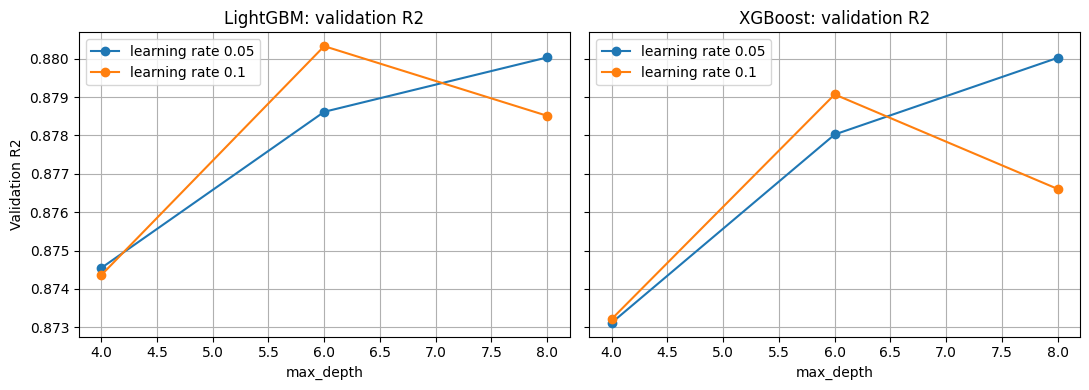

In [ ]:
pivot = tuning.pivot_table(index=["model", "max_depth"], columns="learning_rate", values="valid_R2")
display(pivot.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, model_name in zip(axes, ["LightGBM", "XGBoost"]):
    for lr in learning_rates:
        sub = tuning[(tuning["model"] == model_name) & (tuning["learning_rate"] == lr)]
        ax.plot(sub["max_depth"], sub["valid_R2"], marker="o", label=f"learning rate {lr}")
    ax.set_title(f"{model_name}: validation R2")
    ax.set_xlabel("max_depth")
    ax.grid(True)
    ax.legend()
axes[0].set_ylabel("Validation R2")
plt.tight_layout()
plt.show()


In [ ]:
def make_model(model_name, row):
    if model_name == "LightGBM":
        return lgb.LGBMRegressor(n_estimators=int(row["n_estimators"]), learning_rate=row["learning_rate"],
                                 max_depth=int(row["max_depth"]), num_leaves=min(2 ** int(row["max_depth"]) - 1, 127),
                                 random_state=SEED, n_jobs=-1, verbose=-1)
    return xgb.XGBRegressor(n_estimators=int(row["n_estimators"]), learning_rate=row["learning_rate"],
                            max_depth=int(row["max_depth"]), tree_method="hist", random_state=SEED, n_jobs=-1)

final_rows, fitted, preds = [], {}, {}
for _, row in best.iterrows():
    for set_name, set_cols in feature_sets.items():
        model = make_model(row["model"], row)
        start = time.time()
        model.fit(train[set_cols], y_train)
        p = model.predict(test[set_cols])
        s_test, s_train = score(y_test, p), score(y_train, model.predict(train[set_cols]))
        label = f"{row['model']} (tuned)"
        final_rows.append({"feature_set": set_name, "model": label, "max_depth": int(row["max_depth"]),
                           "learning_rate": row["learning_rate"], "n_estimators": int(row["n_estimators"]),
                           "train_R2": s_train["R2"], "test_R2": s_test["R2"],
                           "test_MAE": s_test["MAE"], "test_RMSE": s_test["RMSE"]})
        fitted[(label, set_name)] = model
        preds[(label, set_name)] = p
        print(f"{set_name:<24} | {label:<18} | train R2 = {s_train['R2']:.4f} | test R2 = {s_test['R2']:.4f} | "
              f"MAE = ${s_test['MAE']:,.0f} | {time.time() - start:.0f}s")

tuned_results = pd.DataFrame(final_rows)
tuned_results.round(4)


Original features        | LightGBM (tuned)   | train R2 = 0.8811 | test R2 = 0.8075 | MAE = $242,125 | 33s
Final features (set 8)   | LightGBM (tuned)   | train R2 = 0.9438 | test R2 = 0.8707 | MAE = $182,482 | 41s
Original features        | XGBoost (tuned)    | train R2 = 0.9249 | test R2 = 0.8135 | MAE = $233,088 | 29s
Final features (set 8)   | XGBoost (tuned)    | train R2 = 0.9683 | test R2 = 0.8732 | MAE = $177,827 | 43s


,feature_set,model,max_depth,learning_rate,n_estimators,train_R2,test_R2,test_MAE,test_RMSE
0,Original features,LightGBM (tuned),6,0.10,760,0.8811,0.8075,242125.2358,570663.3242
1,Final features (set 8),LightGBM (tuned),6,0.10,760,0.9438,0.8707,182482.2740,467702.5881
2,Original features,XGBoost (tuned),8,0.05,759,0.9249,0.8135,233087.9962,561675.8349
3,Final features (set 8),XGBoost (tuned),8,0.05,759,0.9683,0.8732,177826.9640,463049.0622


In [ ]:
week6_file = os.path.join(DATA_DIR, "feature_set_comparison.csv")
if os.path.exists(week6_file):
    old = pd.read_csv(week6_file)
else:
    print("feature_set_comparison.csv not found: showing only the gradient boosting results.")
    old = pd.DataFrame(columns=["feature_set", "model", "train_R2", "test_R2", "test_MAE", "test_RMSE"])
old = old[old["feature_set"].isin(["1. Original features", "8. + distance & nearby prices"])].copy()
old["feature_set"] = old["feature_set"].map({"1. Original features": "Original features",
                                              "8. + distance & nearby prices": "Final features (set 8)"})

new = tuned_results[["feature_set", "model", "train_R2", "test_R2", "test_MAE", "test_RMSE"]]
old = old[["feature_set", "model", "train_R2", "test_R2", "test_MAE", "test_RMSE"]]
all_results = pd.concat([old, new], ignore_index=True)

all_results["feature_set"] = pd.Categorical(all_results["feature_set"], ["Original features", "Final features (set 8)"])
all_results = all_results.sort_values(["feature_set", "test_R2"], ascending=[True, False]).reset_index(drop=True)
all_results["R2_gap (train - test)"] = all_results["train_R2"] - all_results["test_R2"]

display(all_results.round(4))
all_results.to_csv(os.path.join(DATA_DIR, "advanced_models_results.csv"), index=False)
print("Saved advanced_models_results.csv")


,feature_set,model,train_R2,test_R2,test_MAE,test_RMSE,R2_gap (train - test)
0,Original features,XGBoost (tuned),0.9249,0.8135,233087.9962,561675.8349,0.1114
1,Original features,LightGBM (tuned),0.8811,0.8075,242125.2358,570663.3242,0.0736
2,Original features,Random Forest (100 trees),0.8725,0.7521,262836.0378,647520.3315,0.1204
3,Original features,Decision Tree (depth 20),0.9452,0.5844,327849.7869,838458.0994,0.3608
4,Original features,Linear Regression,0.4920,0.4800,515188.7481,937892.6865,0.0120
5,Final features (set 8),XGBoost (tuned),0.9683,0.8732,177826.9640,463049.0622,0.0951
6,Final features (set 8),LightGBM (tuned),0.9438,0.8707,182482.2740,467702.5881,0.0731
7,Final features (set 8),Random Forest (100 trees),0.9372,0.8568,184729.3040,492140.8730,0.0803
8,Final features (set 8),Linear Regression,0.8442,0.8265,217324.3740,541786.5955,0.0177
9,Final features (set 8),Decision Tree (depth 20),0.9816,0.7359,235983.2761,668429.8436,0.2457


Saved advanced_models_results.csv


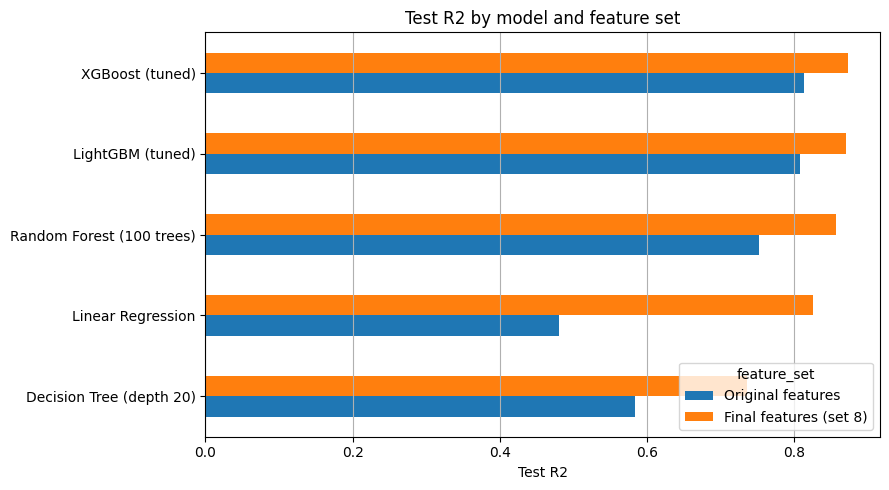

In [ ]:
plot_df = all_results.pivot(index="model", columns="feature_set", values="test_R2")
plot_df = plot_df.sort_values("Final features (set 8)")
plot_df.plot(kind="barh", figsize=(9, 5))
plt.title("Test R2 by model and feature set")
plt.xlabel("Test R2")
plt.ylabel("")
plt.grid(axis="x")
plt.tight_layout()
plt.show()


Best tuned model: XGBoost (tuned) | test R2 = 0.8732 | MAE = $ 177827


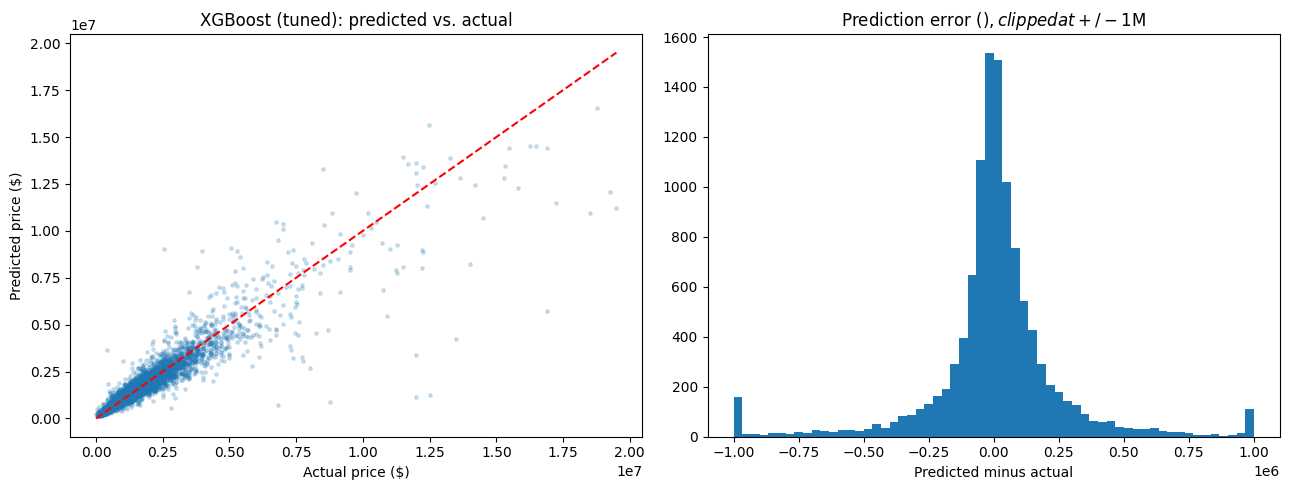

In [ ]:
final_only = tuned_results[tuned_results["feature_set"] == "Final features (set 8)"]
best_row = final_only.loc[final_only["test_R2"].idxmax()]
best_label = best_row["model"]
print("Best tuned model:", best_label, "| test R2 =", round(best_row["test_R2"], 4),
      "| MAE = $", round(best_row["test_MAE"]))

p = preds[(best_label, "Final features (set 8)")]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, p, alpha=0.2, s=6)
lim = max(y_test.max(), p.max())
axes[0].plot([0, lim], [0, lim], color="red", linestyle="--")
axes[0].set_title(f"{best_label}: predicted vs. actual")
axes[0].set_xlabel("Actual price ($)")
axes[0].set_ylabel("Predicted price ($)")

errors = p - y_test
axes[1].hist(errors.clip(-1_000_000, 1_000_000), bins=60)
axes[1].set_title("Prediction error ($), clipped at +/- $1M")
axes[1].set_xlabel("Predicted minus actual")
plt.tight_layout()
plt.show()


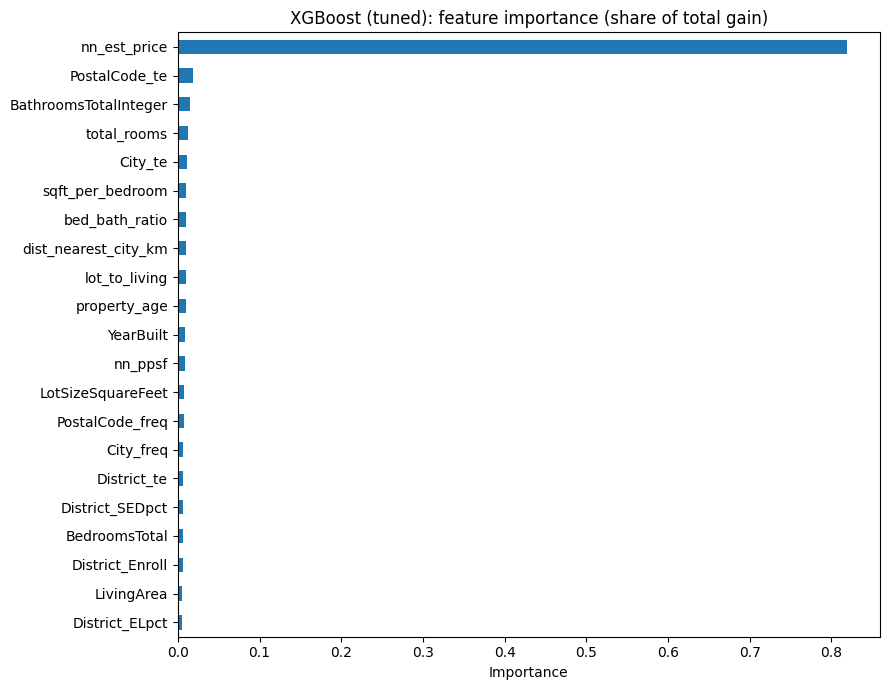

,0
nn_est_price,0.8186
PostalCode_te,0.0181
BathroomsTotalInteger,0.0152
total_rooms,0.0130
City_te,0.0117
sqft_per_bedroom,0.0101
bed_bath_ratio,0.0099
dist_nearest_city_km,0.0099
lot_to_living,0.0095
property_age,0.0095


In [ ]:
model = fitted[(best_label, "Final features (set 8)")]
if "LightGBM" in best_label:
    importance = pd.Series(model.booster_.feature_importance(importance_type="gain"), index=final_features)
else:
    importance = pd.Series(model.feature_importances_, index=final_features)
importance = (importance / importance.sum()).sort_values()

importance.plot(kind="barh", figsize=(9, 7))
plt.title(f"{best_label}: feature importance (share of total gain)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
importance.sort_values(ascending=False).round(4)


**Findings**

**Results**: Tuned XGBoost was the best model, followed by LightGBM. Both beat the random forest, linear regression, and the decision tree.

**Tuning**: Tuning improved test R^2 only slightly over default settings. Validation R^2 was between 0.873 and 0.880 across all depth and learning rate combinations, so the models are not very sensitive to these settings. The best settings were depth 8 with learning rate 0.05 for XGBoost, and depth 6 with learning rate 0.10 for LightGBM, using about 760 trees found by early stopping.

**Feature vs. models** The features helped more than switching models. The nearby-price estimate carries about 82% of the best model's importance.